# ML screening of MOFs for post-combustion CO₂ capture
Predict **vacuum-swing working capacity** (mmol/g) from structure alone, test whether the model generalises to unseen MOF families, and check how well it would find the best candidates without running the expensive simulations.

**Data:** Boyd et al., *Nature* 2019 — Materials Cloud record 2018.0016 (hypothetical MOFs, GCMC-simulated CO₂ capture, flue gas 0.15 bar CO₂ / 85% N₂).

Run the cells top to bottom (Runtime → Run all, after uploading the data in step 1).

## 0. Setup

In [1]:
!pip -q install shap xgboost

## 1. Load data
Upload `screening_data.tar.gz` (or just the all-MOFs CSV) when prompted. Alternative: put the file in Google Drive, mount it with `from google.colab import drive; drive.mount('/content/drive')`, and set `CSV_PATH` yourself in the next cell.

In [2]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/CO2/all_MOFs_screening_data.csv'

try:
    df = pd.read_csv(file_path)
    print("Successfully loaded data from Google Drive!")
except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found. Please check the path and try again.")
except Exception as e:
    print(f"An error occurred: {e}")

Mounted at /content/drive
Successfully loaded data from Google Drive!


## 2. Config, load and feature engineering
Only **structural** descriptors are used as inputs. Every other column is a simulation *result* (other uptakes, selectivity, heats of adsorption...) and would leak the answer.

50,000 MOFs | 159 features
Target: mean 0.42, std 0.47, range -0.14 to 4.62 mmol/g

Topology counts:
 topology
pcu    31668
nbo     7531
sra     3708
etb     3063
acs     2157
bcu     1288
pts      253
fof      219
tbo       58
the       55


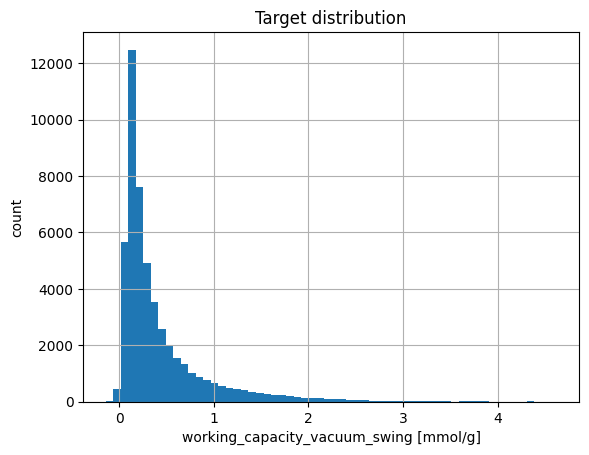

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

TARGET = "working_capacity_vacuum_swing [mmol/g]"
NUMERIC = [
    "volume [A^3]", "weight [u]", "surface_area [m^2/g]", "void_fraction", "void_volume [cm^3/g]",
    "largest_free_sphere_diameter [A]",
    "largest_included_sphere_along_free_sphere_path_diameter [A]",
    "largest_included_sphere_diameter [A]",
]
CATEGORICAL = ["topology", "metal_linker", "organic_linker1", "organic_linker2"]  # IDs, not magnitudes
FUNC_COL = "functional_groups"   # e.g. "H-OPr" -> one flag per group
N_MAX = 50_000                  # rows we're using
SEED = 0

def enrichment(y_true, y_pred, frac):
    """Share of the truly best `frac` of MOFs that also appear in the model's top `frac`."""
    k = max(1, int(len(y_true) * frac))
    true_top = set(np.argsort(-np.asarray(y_true))[:k])
    pred_top = set(np.argsort(-np.asarray(y_pred))[:k])
    return len(true_top & pred_top) / k

df = df.dropna(subset=[TARGET])
if len(df) > N_MAX:
    df = df.sample(N_MAX, random_state=SEED)
df = df.reset_index(drop=True)

parts = [df[NUMERIC].astype(float), pd.get_dummies(df[CATEGORICAL].astype(str), dtype=float)]
parts.append(df[FUNC_COL].fillna("").str.get_dummies(sep="-").add_prefix("fg_").astype(float))
X = pd.concat(parts, axis=1)
X.columns = [str(c).replace('[', '(').replace(']', ')').replace('<', 'lt') for c in X.columns]  #I hate XGB
y = df[TARGET]

print(f"{len(df):,} MOFs | {X.shape[1]} features")
print(f"Target: mean {y.mean():.2f}, std {y.std():.2f}, range {y.min():.2f} to {y.max():.2f} mmol/g")
print("\nTopology counts:\n", df["topology"].value_counts().to_string())
y.hist(bins=60); plt.xlabel(TARGET); plt.ylabel("count"); plt.title("Target distribution"); plt.show()

## 3. Baseline models — random split
Random Forest vs XGBoost on a random 80/20 split. This is the *optimistic* estimate: test MOFs share topology and linkers with training MOFs.

In [4]:
idx = np.arange(len(df))
tr, te = train_test_split(idx, test_size=0.2, random_state=SEED)

def report(name, y_true, y_pred):
    print(f"{name:<22} R2 = {r2_score(y_true, y_pred):6.3f} | MAE = {mean_absolute_error(y_true, y_pred):.3f} mmol/g")

rf = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED).fit(X.iloc[tr], y.iloc[tr])
xgb = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=7, subsample=0.8,
                   colsample_bytree=0.8, n_jobs=-1, random_state=SEED, tree_method = "hist", device = "cuda").fit(X.iloc[tr], y.iloc[tr])
p_rf, p_xgb = rf.predict(X.iloc[te]), xgb.predict(X.iloc[te])
report("Random Forest", y.iloc[te], p_rf)
report("XGBoost", y.iloc[te], p_xgb)

Random Forest          R2 =  0.824 | MAE = 0.110 mmol/g
XGBoost                R2 =  0.856 | MAE = 0.100 mmol/g


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [11:12:01] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


## 4. Harder test — leave one topology out
Train on all topologies except one, then predict the held-out one. This asks: *does the model learn transferable structure–property rules, or just memorise families?* Only topologies with enough MOFs are tested. For each held-out family we also report **enrichment**: how many of that family's truly best 5% / 10% MOFs the model finds in its own top 5% / 10% (random picking would find 5% / 10%).

In [5]:
from scipy.stats import spearmanr

rows = []
for t, n in df["topology"].value_counts().items():
    if n < 300:
        continue
    test_mask = (df["topology"] == t).values
    m = XGBRegressor(n_estimators=300, learning_rate=0.08, max_depth=6, subsample=0.8,
                     colsample_bytree=0.8, random_state=SEED,
                     tree_method="hist", device="cuda")
    m.fit(X[~test_mask], y[~test_mask])
    m.set_params(device="cpu")
    p = m.predict(X[test_mask])
    f5, f10 = enrichment(y[test_mask], p, 0.05), enrichment(y[test_mask], p, 0.10)
    rows.append({
        "held-out topology": t, "n": n,
        "R2": r2_score(y[test_mask], p),
        "MAE": mean_absolute_error(y[test_mask], p),
        "true std": y[test_mask].std(),
        "bias (pred-true)": (p - y[test_mask]).mean(),
        "Spearman": spearmanr(y[test_mask], p)[0],
        "found top5%": f5, "enrich@5%": f5 / 0.05,
        "found top10%": f10, "enrich@10%": f10 / 0.10,
    })
loto = pd.DataFrame(rows).round(3)
loto

,held-out topology,n,R2,MAE,true std,bias (pred-true),Spearman,found top5%,enrich@5%,found top10%,enrich@10%
0,pcu,31668,0.237,0.246,0.429,0.060,0.655,0.298,5.963,0.373,3.733
1,nbo,7531,-0.503,0.096,0.099,0.092,0.780,0.577,11.543,0.661,6.614
2,sra,3708,0.463,0.351,0.728,-0.119,0.762,0.443,8.865,0.500,5.000
3,etb,3063,-1.933,0.276,0.203,0.201,0.276,0.163,3.268,0.219,2.190
4,acs,2157,0.367,0.317,0.554,-0.200,0.751,0.234,4.673,0.363,3.628
5,bcu,1288,0.421,0.276,0.575,-0.243,0.910,0.219,4.375,0.453,4.531


## 5. Does it find the best MOFs? (enrichment)
In a real screen you only care about the *top* candidates. Take the model's top-k% predictions on the test set and measure how many of the *truly* best k% MOFs it captured. Picking at random would capture k%.

In [6]:
# enrichment() is defined in the config cell (section 2)
rows = []
for frac in [0.01, 0.05, 0.10]:
    hit = enrichment(y.iloc[te], p_xgb, frac)
    rows.append({"top fraction": f"{frac:.0%}", "found by model": f"{hit:.0%}",
                 "random baseline": f"{frac:.0%}", "enrichment": f"{hit/frac:.1f}x"})
pd.DataFrame(rows)

,top fraction,found by model,random baseline,enrichment
0,1%,65%,1%,65.0x
1,5%,72%,5%,14.3x
2,10%,79%,10%,7.9x


## 5b. How stable are these numbers? (repeat over 5 random splits)
Everything above uses one train/test split, so a lucky or unlucky split could move the numbers. Here the XGBoost baseline is retrained on 5 different random 80/20 splits; the table at the bottom gives the mean and standard deviation. Quote these in the README instead of the single-split values.

In [7]:
idx = np.arange(len(df))
rows = []
for seed in range(5):
    a_, b_ = train_test_split(idx, test_size=0.2, random_state=seed)
    m = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=7, subsample=0.8,
                     colsample_bytree=0.8, n_jobs=-1, random_state=seed,
                     tree_method="hist", device="cuda")
    m.fit(X.iloc[a_], y.iloc[a_])
    m.set_params(device="cpu")          # avoids the device-mismatch warning at predict time
    p = m.predict(X.iloc[b_])
    rows.append({
        "seed": seed,
        "R2": r2_score(y.iloc[b_], p),
        "MAE": mean_absolute_error(y.iloc[b_], p),
        "found top1%": enrichment(y.iloc[b_], p, 0.01),
        "found top5%": enrichment(y.iloc[b_], p, 0.05),
        "found top10%": enrichment(y.iloc[b_], p, 0.10),
    })
seed_results = pd.DataFrame(rows).set_index("seed").round(3)
display(seed_results)
print("Mean +/- std over 5 splits:")
display(seed_results.agg(["mean", "std"]).round(3))

,R2,MAE,found top1%,found top5%,found top10%
seed,,,,,
0,0.856,0.100,0.65,0.716,0.792
1,0.864,0.099,0.61,0.738,0.798
2,0.856,0.100,0.65,0.732,0.789
3,0.860,0.099,0.64,0.724,0.782
4,0.859,0.099,0.65,0.728,0.794


Mean +/- std over 5 splits:


,R2,MAE,found top1%,found top5%,found top10%
mean,0.859,0.099,0.640,0.728,0.791
std,0.003,0.001,0.017,0.008,0.006


## 6. Which structural features matter? (SHAP)

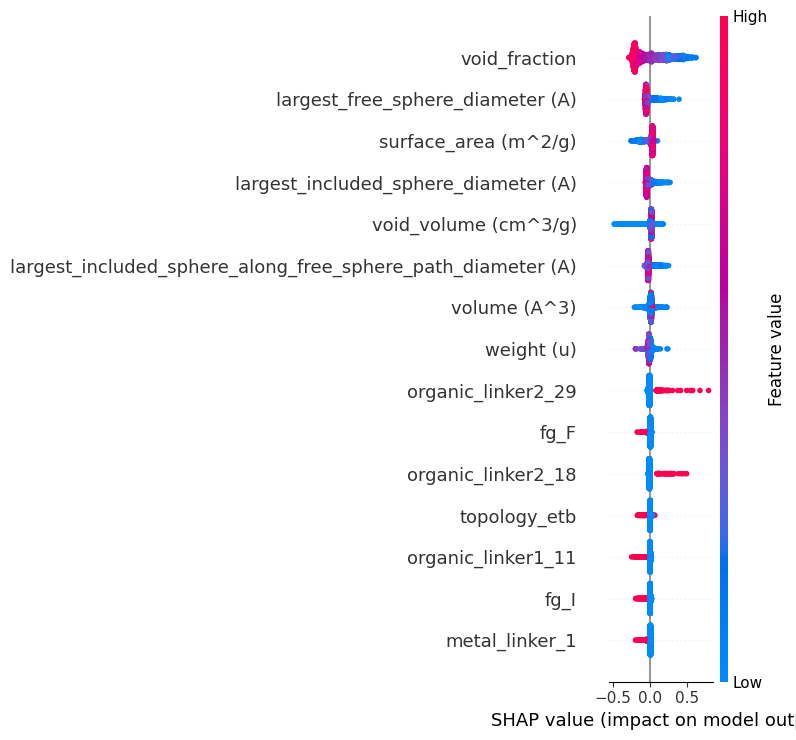

In [8]:
import shap
sample = X.iloc[te].sample(min(2000, len(te)), random_state=SEED)
explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(sample)
shap.summary_plot(sv, sample, max_display=15, show=False)
plt.tight_layout(); plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Capacity vs selectivity trade-off
A good adsorbent needs both. The black line is the Pareto front of the simulated values, computed only for MOFs with working capacity ≥ 0.5 mmol/g (selectivity is a ratio of two simulated uptakes and becomes extremely noisy when capacity is near zero); the y-axis is log-scaled; orange points are MOFs the model ranked in its predicted top 5% by capacity (test set only).

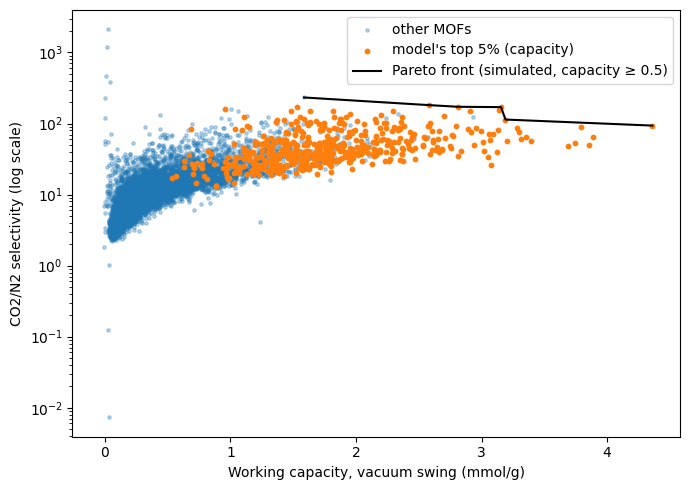

Pareto-optimal MOFs in the test set (capacity >= 0.5): 6


In [9]:
SEL = "CO2/N2_selectivity"
test = df.iloc[te].copy()
test["pred_wc"] = p_xgb
cut = test["pred_wc"].quantile(0.95)
picked = test["pred_wc"] >= cut

def pareto_front(a, b):
    # maximise both a and b
    order = np.argsort(-a)
    best_b, keep = -np.inf, []
    for i in order:
        if b[i] > best_b:
            keep.append(i); best_b = b[i]
    return np.array(keep)

a, b = test[TARGET].values, test[SEL].values
MIN_CAP = 0.5   # ignore near-zero-capacity MOFs: their selectivity ratio is extremely noisy
sub = np.where(a >= MIN_CAP)[0]
front = sub[pareto_front(a[sub], b[sub])]
f_sorted = front[np.argsort(a[front])]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(a[~picked.values], b[~picked.values], s=6, alpha=0.3, label="other MOFs")
ax.scatter(a[picked.values], b[picked.values], s=10, c="tab:orange", label="model's top 5% (capacity)")
ax.plot(a[f_sorted], b[f_sorted], "k-", lw=1.5, label=f"Pareto front (simulated, capacity ≥ {MIN_CAP})")
ax.set_xlabel("Working capacity, vacuum swing (mmol/g)"); ax.set_ylabel("CO2/N2 selectivity (log scale)")
ax.set_yscale("log")
ax.legend(); plt.tight_layout(); plt.savefig("pareto.png", dpi=150); plt.show()
print(f"Pareto-optimal MOFs in the test set (capacity >= {MIN_CAP}):", len(front))

In [10]:
good = test[(test[TARGET] >= 2.0) & (test[SEL] >= 100)].sort_values("pred_wc", ascending=False)
print(len(good), "MOFs with capacity >= 2 mmol/g and selectivity >= 100")
good[["MOFname", "topology", "functional_groups", TARGET, "pred_wc", SEL]]

20 MOFs with capacity >= 2 mmol/g and selectivity >= 100


,MOFname,topology,functional_groups,working_capacity_vacuum_swing [mmol/g],pred_wc,CO2/N2_selectivity
33488,str_m5_o4_o16_sra_sym.68,sra,Me-Pr,2.588540,2.831784,102.599496
15578,str_m5_o16_o18_sra_sym.88,sra,F,2.704243,2.700968,129.089376
45768,str_m5_o4_o18_sra_sym.91,sra,OMe-OEt,2.361884,2.580890,105.051852
14163,str_m5_o16_o18_sra_sym.2,sra,Pr,2.200582,2.549939,131.797603
18616,str_m5_o18_o22_sra_sym.69,sra,NHMe,2.810096,2.547817,171.993031
9782,str_m5_o18_o22_sra_sym.11,sra,COOH,3.190393,2.484241,113.643833
40853,str_m5_o2_o18_sra_sym.17,sra,F,3.137044,2.429396,152.663451
30095,str_m2_o5_o17_pcu_sym.36,pcu,NH2-NO2,3.154948,2.258737,169.973645
39115,str_m5_o2_o16_sra_sym.29,sra,OMe,2.297068,2.154739,148.986303
41098,str_m3_o10_o15_pcu_sym.111,pcu,HCO,2.911640,2.124227,148.413127


## 8. Parity plot and candidate shortlist

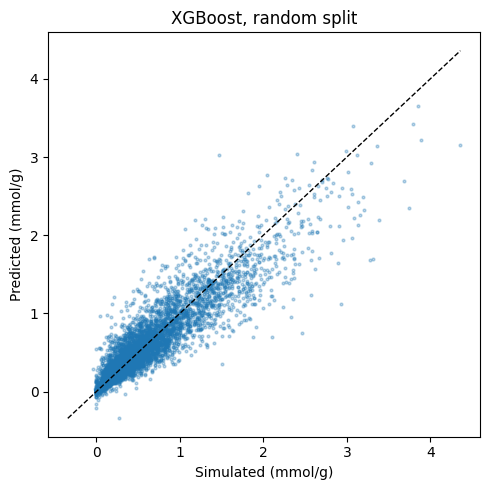

,MOFname,topology,functional_groups,working_capacity_vacuum_swing [mmol/g],pred_wc,CO2/N2_selectivity
17703,str_m2_o10_o29_pcu_sym.53,pcu,OH,3.857854,3.658972,49.957459
4655,str_m5_o4_o18_sra_sym.51,sra,OH,3.788695,3.419562,90.491927
34732,str_m3_o10_o29_pcu_sym.149,pcu,OMe,3.076099,3.396663,26.486219
7827,str_m5_o16_o16_sra_sym.59,sra,OH,3.889095,3.222308,65.047546
47488,str_m5_o10_o29_sra_sym.92,sra,OMe,4.360000,3.152227,93.469643
23963,str_m5_o10_o29_sra_sym.24,sra,OH,3.357205,3.137204,65.280170
9933,str_m5_o1_o18_sra_sym.66,sra,OH-NH2,2.995285,3.076774,79.160258
35122,str_m5_o11_o18_sra_sym.97,sra,OMe,2.399005,3.036504,57.073180
40365,str_m3_o10_o29_pcu_sym.34,pcu,H-NH2,3.124749,3.029535,39.606406
10452,str_m5_o10_o29_sra_sym.176,sra,NO2,1.466780,3.028911,39.090349


In [11]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y.iloc[te], p_xgb, s=4, alpha=0.3)
lims = [min(y.iloc[te].min(), p_xgb.min()), max(y.iloc[te].max(), p_xgb.max())]
ax.plot(lims, lims, "k--", lw=1)
ax.set_xlabel("Simulated (mmol/g)"); ax.set_ylabel("Predicted (mmol/g)"); ax.set_title("XGBoost, random split")
plt.tight_layout(); plt.savefig("parity.png", dpi=150); plt.show()

cols = ["MOFname", "topology", "functional_groups", TARGET, "pred_wc", SEL]
shortlist = test.sort_values("pred_wc", ascending=False)[cols].head(50)
shortlist.to_csv("top_candidates.csv", index=False)
shortlist.head(10)

In [12]:
print("top-5% cutoff on predicted capacity:", round(cut, 2))
good = good.assign(
    in_model_top5 = good["pred_wc"] >= cut,
    pred_percentile = test["pred_wc"].rank(pct=True).loc[good.index].round(3),
)
good[["MOFname", TARGET, "pred_wc", "pred_percentile", "in_model_top5", SEL]]

top-5% cutoff on predicted capacity: 1.35


,MOFname,working_capacity_vacuum_swing [mmol/g],pred_wc,pred_percentile,in_model_top5,CO2/N2_selectivity
33488,str_m5_o4_o16_sra_sym.68,2.588540,2.831784,0.999,True,102.599496
15578,str_m5_o16_o18_sra_sym.88,2.704243,2.700968,0.998,True,129.089376
45768,str_m5_o4_o18_sra_sym.91,2.361884,2.580890,0.997,True,105.051852
14163,str_m5_o16_o18_sra_sym.2,2.200582,2.549939,0.997,True,131.797603
18616,str_m5_o18_o22_sra_sym.69,2.810096,2.547817,0.997,True,171.993031
9782,str_m5_o18_o22_sra_sym.11,3.190393,2.484241,0.996,True,113.643833
40853,str_m5_o2_o18_sra_sym.17,3.137044,2.429396,0.996,True,152.663451
30095,str_m2_o5_o17_pcu_sym.36,3.154948,2.258737,0.994,True,169.973645
39115,str_m5_o2_o16_sra_sym.29,2.297068,2.154739,0.992,True,148.986303
41098,str_m3_o10_o15_pcu_sym.111,2.911640,2.124227,0.992,True,148.413127


## Limitations (copy into your README)
- Labels come from **GCMC simulations on hypothetical structures**, not experiments; force-field and partial-charge errors carry through.
- Screening conditions are a single flue-gas composition at 298 K; **humidity/water competition is not modelled** here.
- Geometry + linker/topology IDs cannot see binding chemistry directly, so transfer to unseen topologies is limited (see section 4).
- No stability, synthesisability or cost information is included.